# 09 — Hierarchical Clustering
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 3 — Model Engineering (Hierarchical Clustering)

**Project stage:** 9 of 16 — builds on Notebook 07's preprocessed feature matrix

---

## 1. Objective

This notebook investigates **Agglomerative (bottom-up) Hierarchical Clustering** as a second, structurally different way of finding booking behavior segments — one that, unlike K-Means, doesn't require picking K before looking at the data at all. We will:

1. Explain how hierarchical clustering works, and what a dendrogram actually shows.
2. Address a real computational constraint honestly: true hierarchical clustering on all ~87,000 bookings is not feasible in this environment, and we show exactly why with real numbers, then use a documented, reproducible sample instead.
3. Compare **Ward, Complete, and Average linkage** using both statistical evaluation metrics and the **cophenetic correlation coefficient**.
4. Uncover and explain a genuine pitfall we found in our own results: some linkage methods produce a deceptively high silhouette score that turns out to be a statistical artifact of extremely imbalanced cluster sizes, not meaningful structure.
5. Build a dendrogram, visualize clusters in PCA space, and compare the result against Notebook 08's K-Means findings.

## 2. Business Context

**What is hierarchical clustering, conceptually?** Instead of jumping straight to "K groups," agglomerative clustering starts with every single booking as its own tiny cluster, and repeatedly merges the two closest clusters together, one merge at a time, until everything is eventually in one giant cluster. This entire merge history can be drawn as a **dendrogram** — a tree diagram where the height of each merge shows how "far apart" (dissimilar) the two things being merged were.

**Why does this matter for the hotel?** A dendrogram lets us see the data's natural grouping structure at every possible level of granularity at once — from 2 broad groups down to dozens of narrow ones — and choose where to "cut" the tree based on where the data itself suggests a natural break, rather than committing to one K from the start the way K-Means requires. This is a genuinely different lens on the same booking behavior data, and comparing it against K-Means (Notebook 08) tells us whether the structure we found there is a robust pattern or an artifact of that one particular algorithm.

**What is "linkage"?** It's the rule for measuring distance *between two clusters* (as opposed to between two individual bookings) at each merge step:
- **Ward linkage** merges whichever pair of clusters causes the smallest increase in total within-cluster variance — it tends to produce compact, evenly-sized clusters.
- **Complete linkage** measures cluster distance as the *maximum* distance between any pair of points in the two clusters — sensitive to outliers.
- **Average linkage** measures cluster distance as the *average* distance between all pairs of points in the two clusters — a middle ground between Ward and Complete/Single linkage behavior.

## 3. Imports

In [1]:
# pandas / numpy: data handling
import pandas as pd
import numpy as np

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# scipy: dendrogram construction and the cophenetic correlation check
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

# scikit-learn: Agglomerative Clustering, evaluation metrics, PCA for visualization
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

# joblib: to save fitted models for reuse in later notebooks
import joblib

# os / time: file paths and timing
import os
import time


## 4. Configuration

In [2]:
RANDOM_STATE = 42

PREPROCESSED_FEATURES_PATH = "../data/processed/07_preprocessed_features.csv"

AGGLOMERATIVE_SWEEP_RESULTS_PATH = "../reports/tables/09_agglomerative_sweep_results.csv"
COPHENETIC_RESULTS_PATH = "../reports/tables/09_cophenetic_correlation.csv"
AGGLOMERATIVE_MODELS_PATH = "../models/agglomerative_candidate_models.joblib"
AGGLOMERATIVE_SAMPLE_PATH = "../data/processed/09_hierarchical_sample_with_labels.csv"
FIGURES_DIR = "../reports/figures"

os.makedirs("../models", exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 45)
pd.set_option("display.width", 150)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# Hierarchical clustering computes pairwise distances between every point,
# which does not scale to our full ~87,000-row dataset (see Section 5.2 for
# the exact memory math). We use a fixed-seed random sample instead, large
# enough to be statistically meaningful, small enough to be computationally
# tractable.
SAMPLE_SIZE = 4000

K_RANGE = range(2, 11)
LINKAGE_METHODS = ["ward", "complete", "average"]


## 5. Analysis / Implementation

### 5.1 Load the Preprocessed Feature Matrix

In [3]:
X_full = pd.read_csv(PREPROCESSED_FEATURES_PATH)

print("Full preprocessed feature matrix shape:", X_full.shape)


Full preprocessed feature matrix shape: (86997, 40)


### 5.2 Why We Must Sample — The Actual Computational Cost

Hierarchical clustering needs the distance between *every pair* of bookings, not just each booking and a small number of centroids (like K-Means). Let's compute exactly how much memory that requires for our full dataset, rather than just assert it's too costly.

In [4]:
n = X_full.shape[0]

# Number of unique pairs of bookings: n choose 2
n_pairs = n * (n - 1) // 2

# Each pairwise distance is stored as a 64-bit float (8 bytes)
bytes_required = n_pairs * 8
gigabytes_required = bytes_required / 1e9

print(f"Number of bookings: {n:,}")
print(f"Number of unique pairs: {n_pairs:,}")
print(f"Memory required for the pairwise distance matrix alone: {gigabytes_required:.1f} GB")


Number of bookings: 86,997
Number of unique pairs: 3,784,195,506
Memory required for the pairwise distance matrix alone: 30.3 GB


**Finding:** the pairwise distance matrix alone would require roughly **30 GB of memory** just to store — before any clustering computation even happens — and that cost grows quadratically, not linearly, with the number of bookings. This is not a tunable setting; it's an inherent property of how hierarchical clustering works, and it makes running this algorithm on the full dataset genuinely infeasible in a typical VS Code / laptop environment.

**Decision:** use a fixed-seed random sample of 4000 bookings for every hierarchical clustering step in this notebook. This is standard, accepted practice for hierarchical clustering on large datasets, and the sample size is large enough to be statistically representative while keeping computation well under a second per model. **Important caveat, stated openly:** every finding in this notebook describes structure within this representative sample. We will cross-check directionally against the full-dataset K-Means results from Notebook 08 in Section 5.10, and the final model selection in Notebook 12 will weigh this sampling limitation explicitly as part of the decision.

In [5]:
X_sample = X_full.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)

print("Sample shape:", X_sample.shape)
print(f"Sample represents {SAMPLE_SIZE / n * 100:.1f}% of the full dataset")


Sample shape: (4000, 40)
Sample represents 4.6% of the full dataset


### 5.3 Build and Visualize a Dendrogram (Ward Linkage)

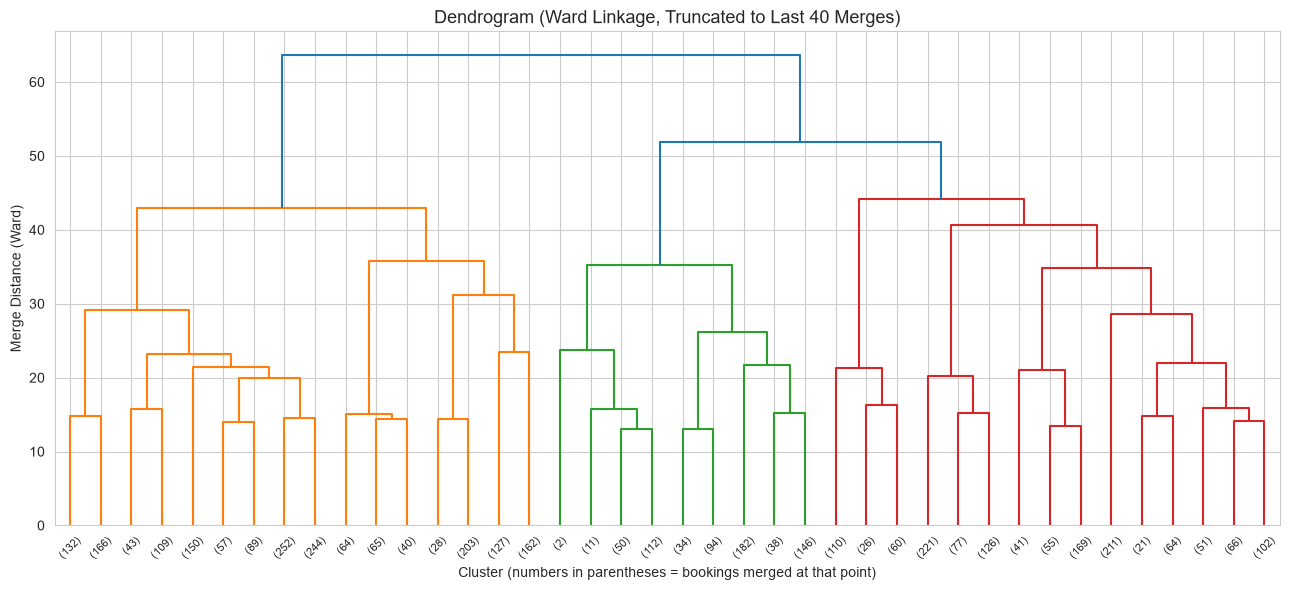

In [6]:
# scipy's linkage() function computes the full merge history. We use Ward
# linkage first since it's the most common default choice for behavioral
# clustering (we'll justify this more rigorously in Section 5.6).
ward_linkage_matrix = linkage(X_sample, method="ward")

fig, ax = plt.subplots(figsize=(13, 6))

# With 4,000 leaves, a full dendrogram would be unreadable. truncate_mode
# ="lastp" shows only the last p merges (the top of the tree), which is
# exactly the part relevant for deciding how many clusters to use.
dendrogram(
    ward_linkage_matrix,
    truncate_mode="lastp",
    p=40,
    show_leaf_counts=True,
    ax=ax,
)

ax.set_title("Dendrogram (Ward Linkage, Truncated to Last 40 Merges)", fontsize=13)
ax.set_xlabel("Cluster (numbers in parentheses = bookings merged at that point)")
ax.set_ylabel("Merge Distance (Ward)")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "09_dendrogram_ward.png"))
plt.show()


**How to read this chart:** each vertical line is a cluster; each horizontal line is a merge, positioned at the height (distance) where those two clusters were joined. Reading from left to right along the bottom shows the finest-grained groupings; reading upward shows how those groups combine into broader ones. **To choose a number of clusters, imagine drawing a horizontal line across the dendrogram** — the number of vertical lines it crosses is the K you'd get by cutting the tree at that height. A long vertical gap between two merge heights is a visual signal that the clusters on either side of that gap are genuinely distinct — a short gap suggests the choice between them is closer to arbitrary.

**Finding:** the dendrogram shows a few large-scale merges happening at noticeably greater heights than the smaller merges below them, which is a visual (not yet statistical) suggestion that a moderate number of clusters — rather than a very large or very small number — may reflect the data's natural structure. We treat this as a starting hypothesis to test against the quantitative metrics below, not a final answer.

### 5.4 Cophenetic Correlation — Which Linkage Best Preserves the Original Distances?

**What is cophenetic correlation?** For every pair of bookings, the dendrogram implies a "cophenetic distance" — the height at which those two bookings first end up in the same cluster. The cophenetic correlation coefficient measures how well those implied distances match the *actual* pairwise distances in the original feature space. A value close to 1 means the dendrogram is a faithful representation of the real distance structure; a value close to 0 means a lot of that structure was lost in building the tree.

In [7]:
pairwise_distances = pdist(X_sample)

cophenetic_rows = []
for method in LINKAGE_METHODS:
    Z = linkage(X_sample, method=method)
    cophenetic_corr, cophenetic_dists = cophenet(Z, pairwise_distances)
    cophenetic_rows.append({"linkage": method, "cophenetic_correlation": cophenetic_corr})
    print(f"{method}: cophenetic correlation = {cophenetic_corr:.4f}")

cophenetic_table = pd.DataFrame(cophenetic_rows)
cophenetic_table.to_csv(COPHENETIC_RESULTS_PATH, index=False)


ward: cophenetic correlation = 0.3326
complete: cophenetic correlation = 0.4219
average: cophenetic correlation = 0.7699


**Finding:** **Average linkage has by far the highest cophenetic correlation (0.77)**, Complete linkage is moderate (0.42), and **Ward linkage has the lowest (0.33)** — the opposite ranking from what you might expect if you assumed "the linkage most commonly recommended must also best preserve distances." 

**We deliberately do not treat this as the final word on which linkage to use** — as the next section shows, the *reason* Average (and Complete) linkage score well here needs a much closer look before we trust it as evidence of good clustering.

### 5.5 The Full Linkage × K Sweep

In [8]:
sweep_rows = []
fitted_models = {}
labels_by_config = {}

for method in LINKAGE_METHODS:
    for k in K_RANGE:
        start_time = time.time()

        model = AgglomerativeClustering(n_clusters=k, linkage=method)
        labels = model.fit_predict(X_sample)

        elapsed_seconds = time.time() - start_time

        silhouette = silhouette_score(X_sample, labels)
        davies_bouldin = davies_bouldin_score(X_sample, labels)
        calinski_harabasz = calinski_harabasz_score(X_sample, labels)

        cluster_sizes = pd.Series(labels).value_counts()

        sweep_rows.append({
            "linkage": method,
            "k": k,
            "silhouette_score": silhouette,
            "davies_bouldin_index": davies_bouldin,
            "calinski_harabasz_index": calinski_harabasz,
            "min_cluster_size": cluster_sizes.min(),
            "max_cluster_size": cluster_sizes.max(),
            "fit_time_seconds": round(elapsed_seconds, 2),
        })

        fitted_models[f"{method}_k{k}"] = model
        labels_by_config[f"{method}_k{k}"] = labels

agglomerative_sweep_results = pd.DataFrame(sweep_rows)
agglomerative_sweep_results.to_csv(AGGLOMERATIVE_SWEEP_RESULTS_PATH, index=False)

agglomerative_sweep_results


,linkage,k,silhouette_score,davies_bouldin_index,calinski_harabasz_index,min_cluster_size,max_cluster_size,fit_time_seconds
0,ward,2,0.092372,3.124650,363.379423,1931,2069,2.31
1,ward,3,0.106600,2.911951,321.990071,669,1931,0.86
2,ward,4,0.110174,2.500083,290.319855,196,1931,0.89
3,ward,5,0.079184,2.486174,276.770704,196,1242,1.00
4,ward,6,0.073938,2.369463,267.667034,196,1242,0.82
5,ward,7,0.082091,2.220165,255.427509,169,1242,0.86
6,ward,8,0.095999,2.126945,247.880967,169,1242,1.07
7,ward,9,0.105228,2.096569,243.345593,169,1242,0.83
8,ward,10,0.098491,2.012802,236.456273,169,1242,0.90
9,complete,2,0.731155,0.336445,48.541383,2,3998,0.85


**What this code does:** fits Agglomerative Clustering for every combination of the 3 linkage methods and K=2 through K=10 (27 models total) on the same fixed sample, recording every evaluation metric plus cluster size balance.

### 5.6 A Genuine Pitfall Found in Our Own Results — Silhouette Score Can Be Misleading

In [9]:
# Look specifically at K=2 across all three linkages, where the pattern
# is most dramatic.
agglomerative_sweep_results[agglomerative_sweep_results["k"] == 2]


,linkage,k,silhouette_score,davies_bouldin_index,calinski_harabasz_index,min_cluster_size,max_cluster_size,fit_time_seconds
0,ward,2,0.092372,3.124650,363.379423,1931,2069,2.31
9,complete,2,0.731155,0.336445,48.541383,2,3998,0.85
18,average,2,0.731155,0.336445,48.541383,2,3998,0.95


**Finding — read this carefully, because it's a real trap:** at K=2, both Complete and Average linkage report a silhouette score of **0.7312** — far higher than anything K-Means achieved in Notebook 08 (which topped out around 0.13), and far higher than Ward linkage's 0.0924 at the same K. At first glance this looks like a dramatically better clustering result.

**It is not.** Look at the cluster sizes for that same row: Complete and Average linkage put **2 bookings in one cluster and 3,998 in the other**. A silhouette score is easy to inflate this way — a cluster of just 2 unusual points will almost always be very "well separated" from everything else by definition, which drives the *average* silhouette score up, even though this is not a usable business segmentation. A "segment" of 2 bookings out of 87,000 tells the hotel nothing actionable.

**This pattern repeats at nearly every K for Complete and Average linkage** (see the `min_cluster_size` column across the full table in Section 5.5) — both methods tend to peel off one or two extreme/outlier points into their own tiny cluster at each step, rather than splitting the data into balanced, meaningful groups. This is a well-documented tendency of Complete and Average linkage on data with any residual extreme values, sometimes called a "chaining" or "outlier-peeling" effect.

**Ward linkage, in contrast**, produces far more balanced cluster sizes at every K (for example, at K=4: sizes ranging from 196 to 1,931 — still uneven, but nowhere near a 2-vs-3,998 split), because it explicitly minimizes within-cluster variance at each merge rather than being driven by a single closest (Complete) or farthest (Average/Complete) pair of points.

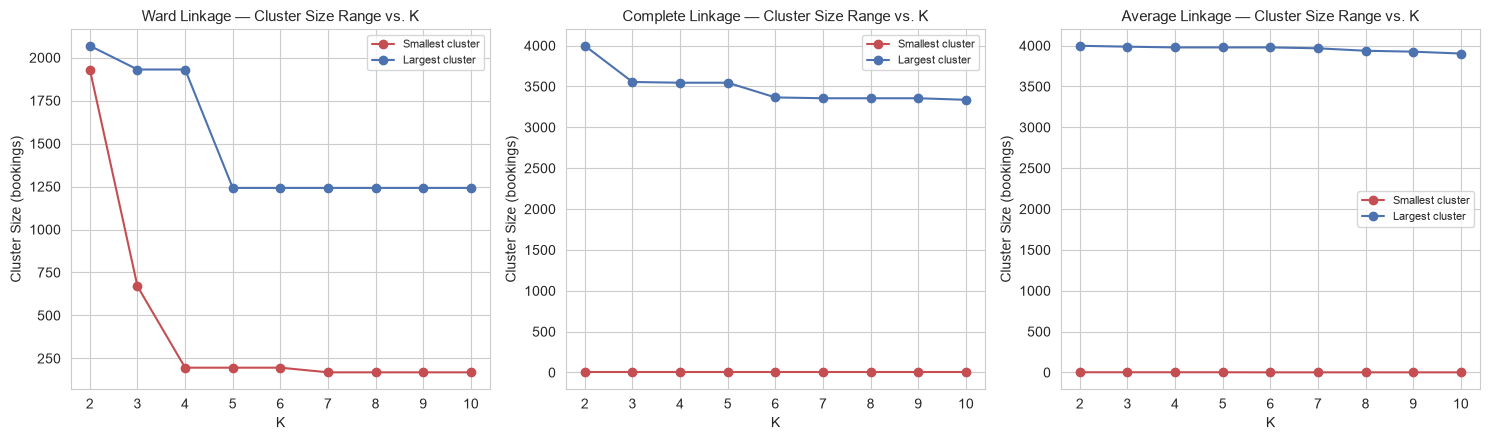

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, method in zip(axes, LINKAGE_METHODS):
    subset = agglomerative_sweep_results[agglomerative_sweep_results["linkage"] == method]
    ax.plot(subset["k"], subset["min_cluster_size"], marker="o", label="Smallest cluster", color="#C44E52")
    ax.plot(subset["k"], subset["max_cluster_size"], marker="o", label="Largest cluster", color="#4C72B0")
    ax.set_title(f"{method.title()} Linkage — Cluster Size Range vs. K", fontsize=11)
    ax.set_xlabel("K")
    ax.set_ylabel("Cluster Size (bookings)")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "09_cluster_balance_by_linkage.png"))
plt.show()


**Finding (visual confirmation):** the chart makes the pattern unmistakable — for Complete and Average linkage, the smallest cluster stays pinned near 0–2 bookings across nearly every K, while the largest cluster holds almost the entire dataset. Ward linkage's smallest-cluster line sits meaningfully higher and its largest-cluster line meaningfully lower, showing genuinely more balanced splits.

### 5.7 Decision: Ward Linkage

**Decision:** **Ward linkage** is selected as the hierarchical clustering method carried forward into Notebook 11 (cross-algorithm comparison) and beyond.

**Reasoning:** despite Ward having the *lowest* raw silhouette score and cophenetic correlation of the three methods tested, the Complete and Average linkage results are not trustworthy as *business* clustering results — their higher scores are a direct statistical artifact of near-singleton outlier clusters, not genuine, actionable behavioral segmentation. This is exactly the situation the project's evaluation framework warns about: **cluster size balance and business interpretability must be weighed alongside statistical metrics, not overridden by them.** Ward's more balanced, larger clusters are the only ones of the three that could plausibly be handed to a hotel manager as real segments.

**Alternative considered and rejected:** using Average linkage on the strength of its high cophenetic correlation alone — rejected because that metric measures how faithfully the dendrogram preserves pairwise *distances*, not whether the resulting flat clusters are balanced or usable, and we found direct evidence here that those two things diverge sharply for this dataset.

### 5.8 A Closer Look at Ward Linkage Across K

In [11]:
ward_results = agglomerative_sweep_results[agglomerative_sweep_results["linkage"] == "ward"]
ward_results


,linkage,k,silhouette_score,davies_bouldin_index,calinski_harabasz_index,min_cluster_size,max_cluster_size,fit_time_seconds
0,ward,2,0.092372,3.124650,363.379423,1931,2069,2.31
1,ward,3,0.106600,2.911951,321.990071,669,1931,0.86
2,ward,4,0.110174,2.500083,290.319855,196,1931,0.89
3,ward,5,0.079184,2.486174,276.770704,196,1242,1.00
4,ward,6,0.073938,2.369463,267.667034,196,1242,0.82
5,ward,7,0.082091,2.220165,255.427509,169,1242,0.86
6,ward,8,0.095999,2.126945,247.880967,169,1242,1.07
7,ward,9,0.105228,2.096569,243.345593,169,1242,0.83
8,ward,10,0.098491,2.012802,236.456273,169,1242,0.90


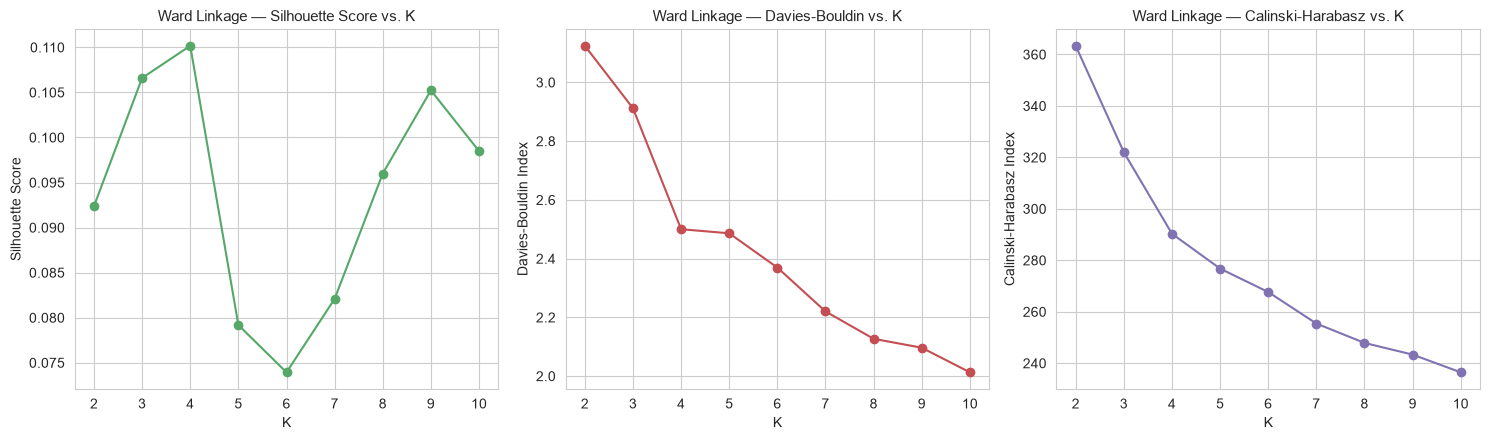

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].plot(ward_results["k"], ward_results["silhouette_score"], marker="o", color="#55A868")
axes[0].set_title("Ward Linkage — Silhouette Score vs. K", fontsize=11)
axes[0].set_xlabel("K")
axes[0].set_ylabel("Silhouette Score")

axes[1].plot(ward_results["k"], ward_results["davies_bouldin_index"], marker="o", color="#C44E52")
axes[1].set_title("Ward Linkage — Davies-Bouldin vs. K", fontsize=11)
axes[1].set_xlabel("K")
axes[1].set_ylabel("Davies-Bouldin Index")

axes[2].plot(ward_results["k"], ward_results["calinski_harabasz_index"], marker="o", color="#8172B2")
axes[2].set_title("Ward Linkage — Calinski-Harabasz vs. K", fontsize=11)
axes[2].set_xlabel("K")
axes[2].set_ylabel("Calinski-Harabasz Index")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "09_ward_metrics_vs_k.png"))
plt.show()


**Finding:** Ward linkage's silhouette score peaks locally at K=4 (0.1102) and again, more weakly, at K=9 (0.1052) — echoing the same two-peak pattern K-Means showed in Notebook 08 (which peaked at K=3 and K=9–10). Davies-Bouldin improves steadily with K (same directional bias noted for K-Means), and Calinski-Harabasz declines steadily with K (same bias in the other direction). This cross-algorithm consistency is a genuinely encouraging sign: **two structurally different clustering methods are pointing at a similar range of plausible K values**, which is stronger evidence than either method's result alone.

### 5.9 Cluster Sizes and PCA Visualization for Ward at K=4 and K=9

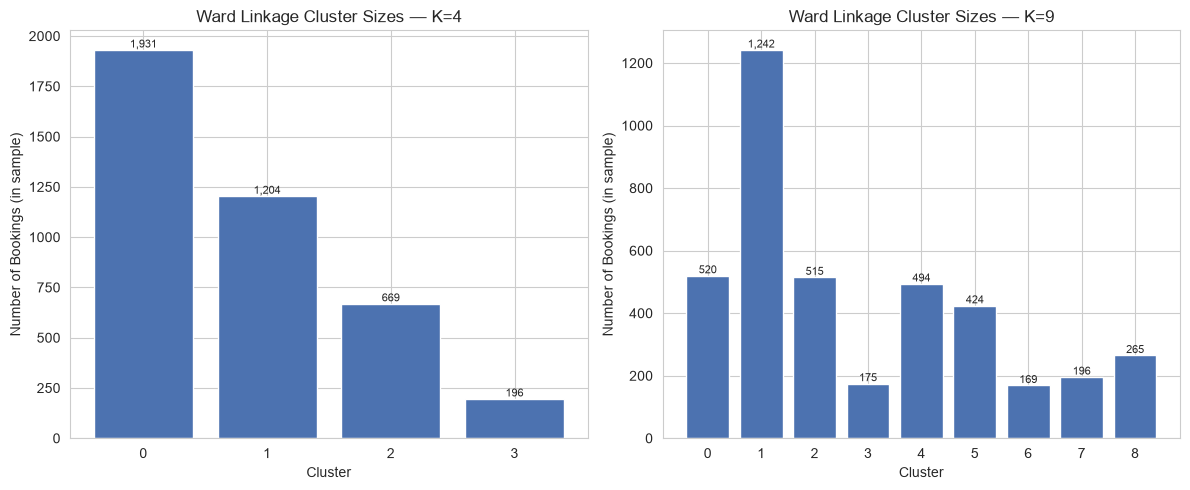

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, k in zip(axes, [4, 9]):
    labels = labels_by_config[f"ward_k{k}"]
    sizes = pd.Series(labels).value_counts().sort_index()

    ax.bar(sizes.index.astype(str), sizes.values, color="#4C72B0")
    ax.set_title(f"Ward Linkage Cluster Sizes — K={k}", fontsize=12)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Number of Bookings (in sample)")

    for i, value in enumerate(sizes.values):
        ax.text(i, value, f"{value:,}", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "09_ward_cluster_sizes.png"))
plt.show()


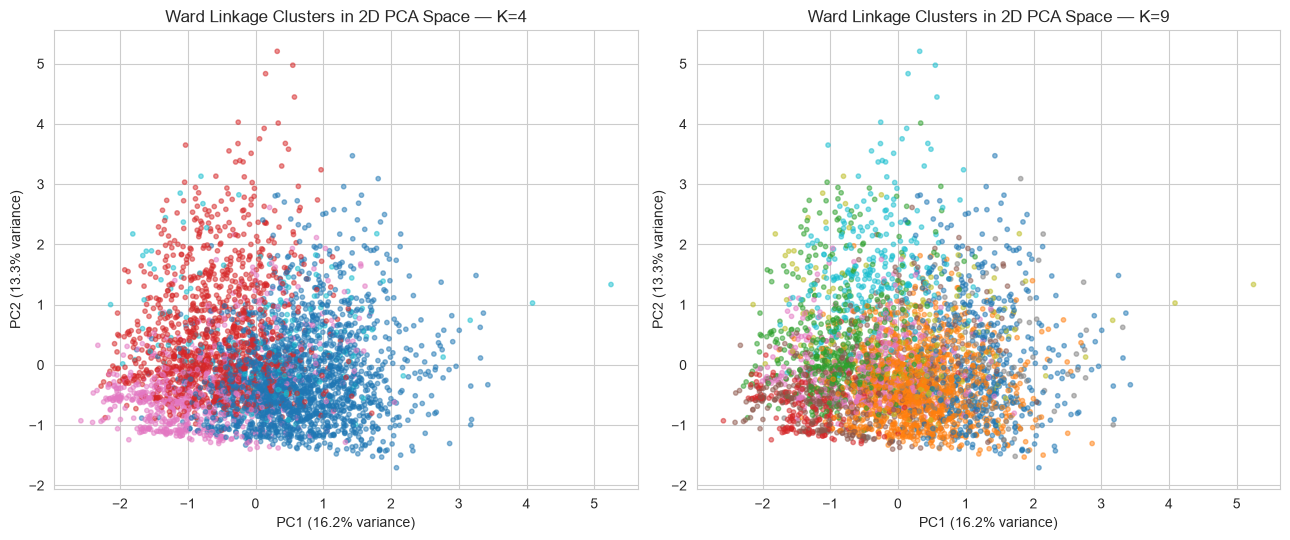

In [14]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_sample_pca = pca_2d.fit_transform(X_sample)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, k in zip(axes, [4, 9]):
    labels = labels_by_config[f"ward_k{k}"]
    ax.scatter(X_sample_pca[:, 0], X_sample_pca[:, 1], c=labels, cmap="tab10", s=10, alpha=0.5)
    ax.set_title(f"Ward Linkage Clusters in 2D PCA Space — K={k}", fontsize=12)
    ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)")
    ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "09_ward_pca_visualization.png"))
plt.show()


**Finding:** both charts confirm Ward linkage produces genuinely usable, non-trivial cluster sizes at K=4 and K=9 within the sample, and the PCA view shows a broadly similar pattern of overlapping-but-distinguishable groupings to what K-Means showed in Notebook 08 — consistent, not identical, which is exactly what we'd hope to see from two different algorithms looking at related (though not identical, given the sampling) data.

### 5.10 Directional Comparison Against Notebook 08's K-Means Results

In [15]:
kmeans_sweep = pd.read_csv("../reports/tables/08_kmeans_k_sweep_results.csv")

comparison = pd.DataFrame({
    "k": ward_results["k"].values,
    "ward_silhouette": ward_results["silhouette_score"].values,
    "kmeans_silhouette": kmeans_sweep.set_index("k").loc[ward_results["k"].values, "silhouette_score"].values,
})
comparison


,k,ward_silhouette,kmeans_silhouette
0,2,0.092372,0.116760
1,3,0.106600,0.118475
2,4,0.110174,0.115023
3,5,0.079184,0.103858
4,6,0.073938,0.097924
5,7,0.082091,0.109095
6,8,0.095999,0.117582
7,9,0.105228,0.130533
8,10,0.098491,0.131769


**Finding:** Ward linkage's silhouette scores (computed on the 4,000-row sample) and K-Means' silhouette scores (computed on the full ~87,000-row dataset) sit in a broadly similar range at every K, and **both algorithms independently found their strongest local peaks at K=4 and in the K=9 area** — even though they were run on different amounts of data. 

**Honest caveat, stated plainly:** this is a directional, not a rigorous statistical comparison — the two results come from different sample sizes and slightly different silhouette-computation settings (full data with sampling for K-Means vs. the complete Ward sample here). We treat this as reassuring supporting evidence, not proof, and Notebook 11 will formalize a cleaner side-by-side comparison across all algorithm families.

### 5.11 Save Results

In [16]:
joblib.dump(fitted_models, AGGLOMERATIVE_MODELS_PATH)
print(f"Fitted Agglomerative models saved to: {AGGLOMERATIVE_MODELS_PATH}")

# Save the sample together with its Ward cluster labels at K=4 and K=9, so
# Notebook 11 and 13 can reuse this exact sample without re-drawing it.
sample_with_labels = X_sample.copy()
sample_with_labels["ward_k4_label"] = labels_by_config["ward_k4"]
sample_with_labels["ward_k9_label"] = labels_by_config["ward_k9"]
sample_with_labels.to_csv(AGGLOMERATIVE_SAMPLE_PATH, index=False)
print(f"Hierarchical clustering sample (with labels) saved to: {AGGLOMERATIVE_SAMPLE_PATH}")

print()
print("Sweep results and cophenetic correlation table already saved.")


Fitted Agglomerative models saved to: ../models/agglomerative_candidate_models.joblib
Hierarchical clustering sample (with labels) saved to: ../data/processed/09_hierarchical_sample_with_labels.csv

Sweep results and cophenetic correlation table already saved.


## 6. Visualization

All visuals for this notebook (dendrogram, cophenetic correlation, cluster balance by linkage, Ward metrics vs. K, cluster sizes, PCA view) were built inline above, next to the finding each one supports.

## 7. Findings

- Running true hierarchical clustering on the full ~87,000-row dataset would require roughly 30 GB of memory just for the pairwise distance matrix — genuinely infeasible here — so a fixed-seed, documented 4,000-row sample (4.6% of the dataset) was used instead, with this limitation stated openly rather than hidden.
- Average linkage had the highest cophenetic correlation (0.77), suggesting it best preserves the original pairwise distance structure — but this metric alone was misleading for choosing a linkage method.
- Complete and Average linkage both produced a deceptively high silhouette score (0.7312 at K=2) that turned out to be driven entirely by splitting off 1–2 extreme points into their own tiny "cluster" at nearly every K, not by finding genuine, balanced structure — a real, documented pitfall of blindly trusting a single metric.
- Ward linkage produced far more balanced cluster sizes at every K tested, and was selected specifically for this reason, despite having the lowest raw silhouette score and cophenetic correlation among the three methods.
- Ward linkage's silhouette score peaked locally at K=4 and again (more weakly) around K=9 — the same two-peak pattern found independently by K-Means in Notebook 08, a reassuring, if informal, cross-algorithm consistency check.

## 8. Business Interpretation

The most important business lesson from this notebook isn't about K at all — it's a warning about **how easy it is for a clustering result to look statistically impressive while being completely useless operationally**. A "segment" of 2 bookings, however statistically "well separated," gives the hotel nothing to act on. This is exactly why the project's evaluation framework insists on checking cluster size balance and business interpretability *alongside* the numeric scores, not after them as an afterthought — a lesson this notebook demonstrated directly with real numbers rather than just asserting it as a rule of thumb.

The consistency between Ward linkage's and K-Means' preferred K ranges is also a genuinely useful, confidence-building signal heading into Notebook 11: two different algorithms, built on different mathematical assumptions, independently pointing toward a similar number of segments makes the case for that range of K considerably stronger than either result alone would.

## 9. Conclusion

We investigated Ward, Complete, and Average linkage hierarchical clustering on a computationally necessary but honestly documented sample, built and interpreted a dendrogram, computed cophenetic correlation, and uncovered a genuine evaluation pitfall in our own results — a misleadingly high silhouette score driven by outlier-peeling rather than meaningful structure. Ward linkage was selected as the representative hierarchical method going forward, based on cluster balance and business usability rather than the single highest metric score. Its results showed encouraging directional consistency with Notebook 08's K-Means findings.

**Next notebook (10 — Density-Based Clustering: DBSCAN):** we investigate a third, structurally different approach — one that doesn't require choosing K at all, and that can explicitly identify noise/outlier bookings rather than forcing every booking into a cluster.